| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../11_MACHINE_LEARNING/11_4_Statistical_Learning_Theory.ipynb) | [⏩](../12_DEEP_LEARNING/12_2_Arquitecturas.ipynb) |

# 12.1 Redes neuronales: neuronas, backpropagation y entrenamiento

**Objetivo del cuaderno.** construir una red pequeña, comprobar sus gradientes y aprender una función suave con validación independiente

**Antes de empezar:** derivadas, gradiente, vectores y aprendizaje supervisado. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)
import torch
from torch import nn
torch.manual_seed(42)
torch.set_num_threads(1)
print('PyTorch:', torch.__version__, '| dispositivo: CPU')

PyTorch: 2.14.1+cpu | dispositivo: CPU


## 1. Una neurona como transformación y no linealidad

Una neurona calcula $z=w^Tx+b$ y $a=\sigma(z)$. La transformación afín mezcla entradas; la activación permite relaciones no lineales. Si todas las activaciones son identidad, apilar capas solo produce otra transformación afín.

Un perceptrón multicapa o MLP aplica

$$h^{(0)}=x,\quad h^{(l)}=\sigma_l(W_lh^{(l-1)}+b_l),\quad \hat y=W_Lh^{(L-1)}+b_L.$$

Los pesos forman parámetros $\theta$. Una capa de $d_{in}$ a $d_{out}$ tiene $d_{out}d_{in}+d_{out}$ parámetros. La salida lineal suele ser útil para regresión de valores con signos libres.

## 2. Activaciones y requisitos científicos

ReLU es $\max(0,z)$: simple y con derivada constante por tramos. Tanh es suave y acotada, pero satura y puede reducir gradientes. Sigmoid produce valores entre cero y uno, útil para probabilidades, aunque usarla en muchas capas también puede causar saturación.

Si una pérdida física necesita segundas derivadas espaciales, la suavidad importa. Una red ReLU tiene segunda derivada cero casi en todas partes en una dimensión; esto puede ser inadecuado para representar una PDE fuerte de segundo orden. Tanh u otras activaciones suaves permiten derivadas de mayor orden.

## 3. Visualizar las activaciones y sus derivadas

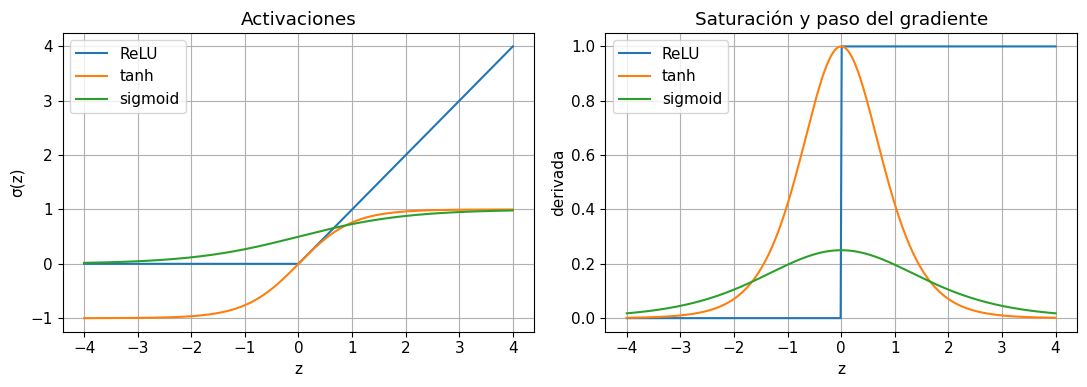

In [2]:
z=np.linspace(-4,4,400)
fig,ax=plt.subplots(1,2,figsize=(11,4))
functions={'ReLU':np.maximum(z,0),'tanh':np.tanh(z),'sigmoid':1/(1+np.exp(-z))}
derivatives={'ReLU':(z>0).astype(float),'tanh':1-np.tanh(z)**2,'sigmoid':functions['sigmoid']*(1-functions['sigmoid'])}
for name in functions:
    ax[0].plot(z,functions[name],label=name);ax[1].plot(z,derivatives[name],label=name)
ax[0].set(xlabel='z',ylabel='σ(z)',title='Activaciones');ax[1].set(xlabel='z',ylabel='derivada',title='Saturación y paso del gradiente')
for a in ax:a.legend()
plt.tight_layout();plt.show()

**Interpretación.** Tanh y sigmoid tienen derivadas pequeñas para entradas de gran magnitud. Si esas derivadas se multiplican muchas veces durante backpropagation, los gradientes hacia las primeras capas pueden volverse pequeños. Normalizar entradas y elegir una inicialización adecuada ayuda, aunque no elimina todos los problemas.

## 4. Forward pass y pérdida

Para regresión con $n$ casos, usamos $J(\theta)=n^{-1}\sum_i(\hat y_i-y_i)^2$. El forward pass calcula la predicción y almacena operaciones. El backward pass aplica la regla de la cadena en sentido inverso para obtener derivadas respecto a parámetros.

En una red de una capa oculta con $a=\tanh(W_1x+b_1)$ y $\hat y=W_2a+b_2$, la pérdida individual $\ell=\tfrac12(\hat y-y)^2$ da $\delta_2=\hat y-y$ y $\delta_1=(W_2^T\delta_2)\odot(1-a^2)$. Los gradientes son productos exteriores: $\partial\ell/\partial W_2=\delta_2a^T$ y $\partial\ell/\partial W_1=\delta_1x^T$.

## 5. Backpropagation a mano: una red mínima

Usamos NumPy para demostrar la derivación y comprobamos una componente mediante diferencias centrales. Esto enseña el cálculo; para entrenar redes complejas usamos autograd.

In [3]:
x=np.array([0.4,-0.7]);W1=np.array([[0.2,-0.3],[0.6,0.1],[0.1,0.5]])
b1=np.array([0.1,0.,-0.2]);W2=np.array([0.5,-0.4,0.3]);b2=0.2;y=0.8
h=np.tanh(W1@x+b1);pred=W2@h+b2
output_error=pred-y;hidden_error=W2*output_error*(1-h*h)
grad_W1=np.outer(hidden_error,x);grad_W2=output_error*h
def toy_loss(W):
    prediction=W2@np.tanh(W@x+b1)+b2
    return 0.5*(prediction-y)**2
eps=1e-6;pert=np.zeros_like(W1);pert[1,0]=eps
numeric=(toy_loss(W1+pert)-toy_loss(W1-pert))/(2*eps)
print('Predicción:',pred,'gradiente W1[1,0]:',grad_W1[1,0],'diferencia central:',numeric)
assert np.isclose(numeric,grad_W1[1,0],rtol=1e-6,atol=1e-9)

Predicción: 0.1773441359100167 gradiente W1[1,0]: 0.09680035441039284 diferencia central: 0.0968003543988516


## 6. Autograd, optimizador y ciclo de entrenamiento

En PyTorch, `nn.Module` contiene capas y parámetros; `loss.backward()` acumula gradientes y `optimizer.step()` actualiza parámetros. `zero_grad()` evita sumar accidentalmente gradientes de iteraciones distintas. `train()` y `eval()` controlan comportamiento de capas como dropout; `no_grad()` desactiva seguimiento de derivadas en evaluación normal.

Para un residual físico que deriva respecto a entradas no usaríamos `no_grad()` alrededor de ese cálculo. El entrenamiento con autograd distingue derivadas de la salida con respecto a parámetros y con respecto a coordenadas.

## 7. Aprender una función: tres conjuntos independientes

La verdad de ejemplo es $f(x)=\sin(\pi x)+0.15x$ en $[-1,1]$. Entrenamos con ruido, seleccionamos la mejor época usando validación y reservamos prueba hasta el final. No elegimos arquitectura ni tasa con el test.

Parámetros entrenables: 673
Mejor época: 939 MSE validación: 0.0048395185731351376


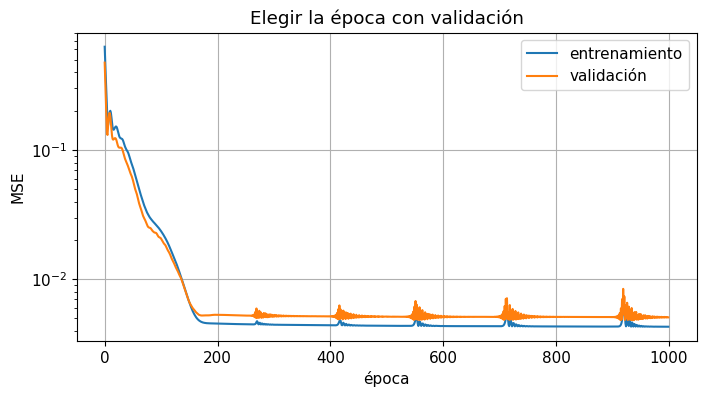

In [4]:
def ftrue(z):return np.sin(np.pi*z)+0.15*z
X=rng.uniform(-1,1,(180,1)).astype(np.float32)
y=(ftrue(X[:,0])+rng.normal(0,0.07,len(X))).astype(np.float32)[:,None]
ids=rng.permutation(len(X));tr,va,te=ids[:110],ids[110:145],ids[145:]
Xt=torch.tensor(X[tr]);yt=torch.tensor(y[tr]);Xv=torch.tensor(X[va]);yv=torch.tensor(y[va])
net=nn.Sequential(nn.Linear(1,24),nn.Tanh(),nn.Linear(24,24),nn.Tanh(),nn.Linear(24,1))
print('Parámetros entrenables:',sum(p.numel() for p in net.parameters()))
optimizer=torch.optim.Adam(net.parameters(),lr=0.01)
train_history=[];val_history=[];best_val=float('inf');best_state=None
for epoch in range(1000):
    net.train();optimizer.zero_grad()
    loss=nn.functional.mse_loss(net(Xt),yt);loss.backward();optimizer.step()
    net.eval()
    with torch.no_grad():v_loss=nn.functional.mse_loss(net(Xv),yv).item()
    train_history.append(loss.item());val_history.append(v_loss)
    if v_loss<best_val:
        best_val=v_loss;best_state={k:v.detach().clone() for k,v in net.state_dict().items()}
net.load_state_dict(best_state);net.eval()
plt.semilogy(train_history,label='entrenamiento');plt.semilogy(val_history,label='validación')
plt.xlabel('época');plt.ylabel('MSE');plt.title('Elegir la época con validación');plt.legend();plt.show()
print('Mejor época:',np.argmin(val_history)+1,'MSE validación:',best_val)

**Interpretación.** La pérdida puede presentar oscilaciones incluso con full batch porque Adam ajusta su memoria y tasa efectiva. Elegimos la época de mínima validación dentro de un presupuesto fijo; esto es selección de modelo. Si la curva de entrenamiento siguiera bajando mientras validación empeora, sería una señal de sobreajuste.

## 8. Predicción y evaluación independiente

Los tensores tienen forma `(n, 1)` para que la salida y la etiqueta coincidan. Usar accidentalmente `(n,)` frente a `(n,1)` puede provocar broadcasting y una pérdida equivocada. Evaluamos sin crear un grafo porque aquí solo necesitamos valores.

RMSE prueba: 0.07819116


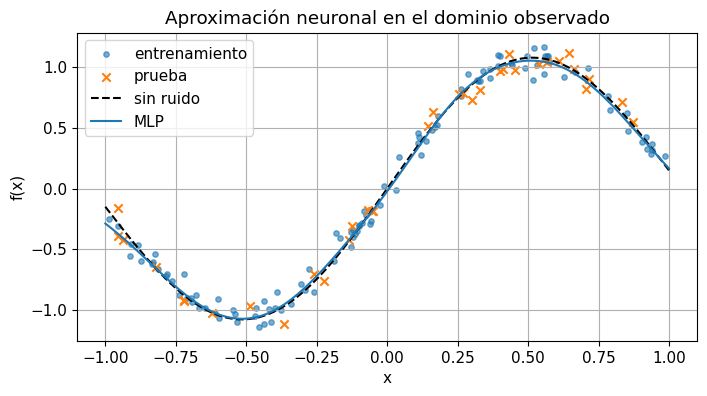

In [5]:
grid=np.linspace(-1,1,300,dtype=np.float32)[:,None]
with torch.no_grad():
    prediction=net(torch.tensor(grid)).numpy()[:,0]
    test_pred=net(torch.tensor(X[te])).numpy()[:,0]
rmse=np.sqrt(np.mean((test_pred-y[te,0])**2))
plt.scatter(X[tr,0],y[tr,0],s=15,alpha=0.6,label='entrenamiento')
plt.scatter(X[te,0],y[te,0],marker='x',label='prueba')
plt.plot(grid[:,0],ftrue(grid[:,0]),'k--',label='sin ruido');plt.plot(grid[:,0],prediction,label='MLP')
plt.xlabel('x');plt.ylabel('f(x)');plt.title('Aproximación neuronal en el dominio observado');plt.legend();plt.show()
print('RMSE prueba:',rmse)
assert np.isfinite(rmse)

## 9. Derivadas de una red y conexión con PINNs

Una red suave define una función diferenciable en las coordenadas. Podemos evaluar $d\hat f/dx$ con autograd y compararla con $f'(x)=\pi\cos(\pi x)+0.15$. Ajustar bien valores no garantiza ajustar bien derivadas: la pérdida de datos no penaliza directamente su discrepancia.

El truco de `grad_outputs=ones` obtiene derivadas por muestra cuando cada salida depende solo de la entrada de esa muestra. Con capas que mezclan muestras la interpretación requeriría un Jacobiano completo.

RMSE derivada en malla: 0.29060394


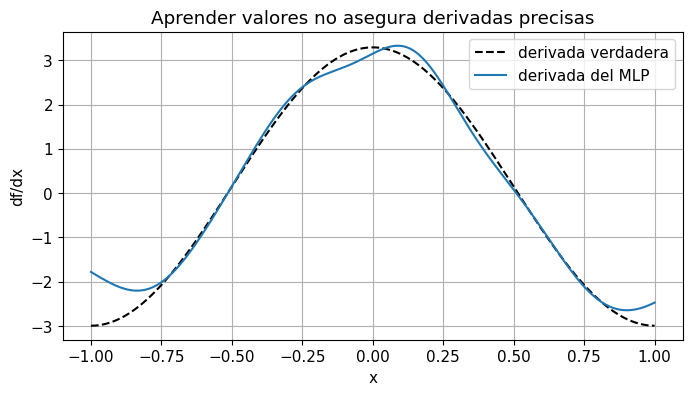

In [6]:
x_der=torch.tensor(grid,requires_grad=True)
out=net(x_der)
der=torch.autograd.grad(out,x_der,grad_outputs=torch.ones_like(out))[0]
true_der=np.pi*np.cos(np.pi*grid[:,0])+0.15
plt.plot(grid[:,0],true_der,'k--',label='derivada verdadera')
plt.plot(grid[:,0],der.detach().numpy()[:,0],label='derivada del MLP')
plt.xlabel('x');plt.ylabel('df/dx');plt.title('Aprender valores no asegura derivadas precisas');plt.legend();plt.show()
print('RMSE derivada en malla:',np.sqrt(np.mean((der.detach().numpy()[:,0]-true_der)**2)))

## 10. Capacidad y extrapolación

Los teoremas de aproximación universal establecen existencia de aproximadores bajo hipótesis específicas; no prometen que SGD encuentre una red útil con pocos datos ni que extrapole. La profundidad y anchura afectan capacidad, coste y representación, pero más parámetros no equivalen a mejor física.

Una función aprendida en un intervalo puede extrapolar de manera incompatible con periodicidad o conservación. Inspecciona dominio, ruido, unidades y regularización antes de interpretar pesos como parámetros científicos.

In [7]:
outside=np.array([[-2.],[-1.5],[1.5],[2.]],dtype=np.float32)
with torch.no_grad():outside_pred=net(torch.tensor(outside)).numpy()[:,0]
print('Diagnóstico fuera del entrenamiento:')
for x0,p0,t0 in zip(outside[:,0],outside_pred,ftrue(outside[:,0])):print(float(x0),'MLP=',round(float(p0),3),'verdad=',round(float(t0),3))

Diagnóstico fuera del entrenamiento:
-2.0 MLP= 0.51 verdad= -0.3
-1.5 MLP= 0.259 verdad= 0.775
1.5 MLP= -0.582 verdad= -0.775
2.0 MLP= -0.772 verdad= 0.3


## 11. Regularización y reproducibilidad del entrenamiento

La regularización L2 añade una penalización de pesos; el decaimiento de pesos implementado por un optimizador puede tener diferencias respecto a esa penalización, especialmente con métodos adaptativos. Dropout introduce aleatoriedad durante entrenamiento y cambia su comportamiento en evaluación. La parada temprana limita cuánto se adapta la red a los datos disponibles.

Para una red usada como función física diferenciable, dropout durante el cálculo de un residual puede introducir ruido adicional; su uso requiere una intención y evaluación claras. En este ejemplo mantenemos una red determinista y elegimos época por validación para poder estudiar valores y derivadas sin esa fuente de variación.

Una semilla fija facilita repetir el caso, pero evaluar robustez requiere varias semillas y conjuntos. Guarda división de datos, arquitectura, activación, tasa de aprendizaje y criterio de selección. Si comparas redes, usa el mismo protocolo y reporta dispersión: el resultado de un solo entrenamiento no describe toda la familia.

## Síntesis y conexión con Scientific Machine Learning

Una red es una composición diferenciable de operaciones parametrizadas. Backpropagation aplica la cadena, un optimizador ajusta parámetros y validación decide qué ajuste conservar. Para SciML importan especialmente suavidad de activaciones, exactitud de derivadas y comportamiento físico fuera de datos.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../11_MACHINE_LEARNING/11_4_Statistical_Learning_Theory.ipynb) | [⏩](../12_DEEP_LEARNING/12_2_Arquitecturas.ipynb) |